# 7 - Proxies de gênero: classificador e SHAP

**Projeto final — SME0828 Introdução à Ciência de Dados**
Prof. Francisco A. Rodrigues — ICMC/USP

Grupo: _(nomes)_

<hr>

No notebook anterior vimos que o modelo de crédito **sem** a variável gênero continua negando mais mulheres que homens. Se o modelo nunca viu o gênero, de onde vem essa diferença?

A explicação é a existência de **proxies**: variáveis que, sem serem o gênero, **carregam informação sobre ele**. Por exemplo, se as mulheres da amostra têm, em média, renda menor, a renda "denuncia" parcialmente o gênero.

Neste notebook vamos:
1. treinar um classificador que tenta **adivinhar o gênero** a partir das variáveis do modelo de crédito. Se ele conseguir, essas variáveis são proxies;
2. usar **SHAP** para descobrir **quais variáveis** mais denunciam o gênero;
3. usar SHAP no modelo de crédito para ver **quais variáveis explicam** a diferença na negação entre mulheres e homens.

### 1. Bibliotecas

O `shap` calcula os **valores SHAP**, que medem quanto cada variável contribuiu para cada previsão de um modelo. Para modelos de árvores, o `shap.TreeExplainer` calcula esses valores de forma exata e rápida.

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore")

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

BLUE   = "#2a78d6"
ORANGE = "#eb6834"
GRAY   = "#898781"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
os.makedirs("../figuras", exist_ok=True)
os.makedirs("../resultados", exist_ok=True)

### 2. Leitura e preparação dos dados

Usamos exatamente a mesma preparação do notebook `05_gradient_boosting` (renda > 0, LTV winsorizado, estado e idade sem faltantes) e a **mesma divisão em treino e teste**, com a mesma semente e a mesma estratificação.

In [2]:
colunas = ["state_code", "income", "combined_loan_to_value_ratio", "loan_type",
           "dti", "applicant_age", "negado", "mulher"]

data = pd.read_parquet("../data/amostra_principal.parquet", columns=colunas)
data = data[data["income"] > 0]
limite_inf, limite_sup = data["combined_loan_to_value_ratio"].quantile([0.001, 0.999])
data["ltv"] = data["combined_loan_to_value_ratio"].clip(limite_inf, limite_sup)
data["log_renda"] = np.log(data["income"])
data = data.dropna(subset=["state_code", "applicant_age"]).reset_index(drop=True)

print("Número de linhas e colunas:", data.shape)

Número de linhas e colunas: (1532885, 10)


### 3. Conversão das variáveis categóricas em inteiros

O `shap` não aceita as categorias em formato de texto que usamos no notebook 05. Por isso, convertemos cada categoria num **número inteiro**, como visto na aula de preparação de dados.

Para DTI e idade, que têm uma **ordem natural**, os números seguem essa ordem (0 = menor faixa). Para estado e tipo de empréstimo, a ordem é arbitrária, mas isso não atrapalha as árvores de decisão, que conseguem separar qualquer conjunto de valores com várias divisões.

In [3]:
ordem_dti = ["<20%", "20%-<30%", "30%-<36%", "36%-<50%", "50%-60%", ">60%"]
ordem_idade = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]

data["dti"] = data["dti"].astype(str).map({faixa: i for i, faixa in enumerate(ordem_dti)})
data["applicant_age"] = data["applicant_age"].map({faixa: i for i, faixa in enumerate(ordem_idade)})
data["loan_type"] = data["loan_type"].astype(int)

estados = sorted(data["state_code"].unique())
data["state_code"] = data["state_code"].map({uf: i for i, uf in enumerate(estados)})

atributos = ["log_renda", "ltv", "dti", "loan_type", "state_code", "applicant_age"]
nomes = {"log_renda": "Renda (log)", "ltv": "LTV", "dti": "DTI", "loan_type": "Tipo de empréstimo",
         "state_code": "Estado", "applicant_age": "Idade"}

data[atributos].head()

,log_renda,ltv,dti,loan_type,state_code,applicant_age
0,4.174387,97.000,3,1,45,1
1,5.181784,80.000,3,1,4,2
2,4.110874,96.500,4,2,4,0
3,4.234107,97.000,1,1,24,1
4,4.077537,98.189,1,2,23,0


Divisão em treino e teste, idêntica à do notebook 05:

In [4]:
estrato = data["negado"].astype(str) + "_" + data["mulher"].astype(str)
treino, teste = train_test_split(data, test_size=0.3, stratify=estrato, random_state=SEMENTE)

print("Treino:", treino.shape)
print("Teste: ", teste.shape)

Treino: (1073019, 10)
Teste:  (459866, 10)


### 4. É possível adivinhar o gênero a partir das outras variáveis?

Treinamos um Gradient Boosting cujo **alvo é o gênero** (`mulher`), usando como entrada **as mesmas variáveis do modelo de crédito sem gênero**. Usamos os mesmos hiperparâmetros escolhidos no notebook 05.

A medida de desempenho é a **AUC**:
- AUC = 0,5: as variáveis **não** carregam informação sobre o gênero (o classificador "chuta");
- quanto mais acima de 0,5, mais as variáveis **denunciam** o gênero.

In [5]:
classificador_genero = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, max_iter=300,
                                                      early_stopping=True, random_state=SEMENTE)
classificador_genero.fit(treino[atributos], treino["mulher"])

proba_mulher = classificador_genero.predict_proba(teste[atributos])[:, 1]
auc_genero = roc_auc_score(teste["mulher"], proba_mulher)
print(f"AUC para prever o gênero: {auc_genero:.4f}")

AUC para prever o gênero: 0.6642


Intervalo de confiança da AUC por **bootstrap** (1.000 reamostragens do conjunto de teste), como no notebook de fairness. Leva alguns minutos.

In [6]:
y_genero = teste["mulher"].values
n = len(y_genero)
aucs = []
for b in range(1000):
    idx = np.random.randint(0, n, n)
    aucs.append(roc_auc_score(y_genero[idx], proba_mulher[idx]))

ic_inf, ic_sup = np.percentile(aucs, [2.5, 97.5])
print(f"AUC = {auc_genero:.4f}  (IC 95%: {ic_inf:.4f} a {ic_sup:.4f})")

AUC = 0.6642  (IC 95%: 0.6627 a 0.6658)


Curva ROC do classificador de gênero. A diagonal cinza representa um classificador que "chuta".

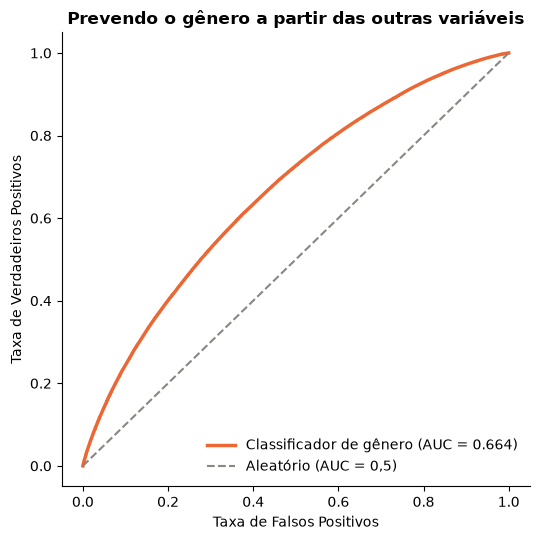

In [7]:
fpr, tpr, _ = roc_curve(teste["mulher"], proba_mulher)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(fpr, tpr, color=ORANGE, linewidth=2.5, label=f"Classificador de gênero (AUC = {auc_genero:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1.5, label="Aleatório (AUC = 0,5)")
ax.set_xlabel("Taxa de Falsos Positivos")
ax.set_ylabel("Taxa de Verdadeiros Positivos")
ax.set_title("Prevendo o gênero a partir das outras variáveis", fontsize=12, fontweight="bold")
ax.legend(frameon=False, loc="lower right")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/proxies_roc_genero.png", dpi=150)
plt.show()

### 5. Quais variáveis denunciam o gênero? (SHAP)

Para cada previsão, o SHAP distribui "o mérito" entre as variáveis: o valor SHAP de uma variável diz **quanto ela empurrou a previsão** para cima (mais chance de ser mulher) ou para baixo.

A **importância** de cada variável é a **média do valor absoluto** dos valores SHAP: quanto maior, mais a variável influencia a previsão do gênero. Calculamos os valores SHAP numa amostra de 50 mil pedidos do teste, o que é suficiente e bem mais rápido.

In [8]:
amostra = teste.sample(n=50_000, random_state=SEMENTE)

explicador_genero = shap.TreeExplainer(classificador_genero)
shap_genero = explicador_genero(amostra[atributos])

importancia_genero = pd.Series(np.abs(shap_genero.values).mean(axis=0), index=atributos)
importancia_genero = importancia_genero.sort_values(ascending=False).rename(index=nomes)
importancia_genero.round(4)

Renda (log)           0.2546
Idade                 0.2468
Tipo de empréstimo    0.1986
Estado                0.0763
LTV                   0.0559
DTI                   0.0495
dtype: float64

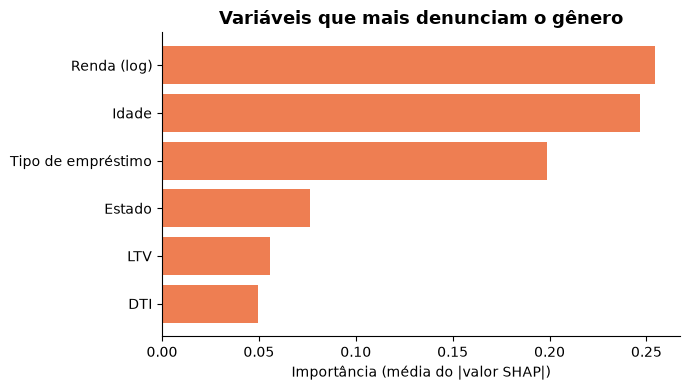

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importancia_genero.index[::-1], importancia_genero.values[::-1], color=ORANGE, alpha=0.85)
ax.set_xlabel("Importância (média do |valor SHAP|)")
ax.set_title("Variáveis que mais denunciam o gênero", fontsize=13, fontweight="bold")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/proxies_importancia_shap.png", dpi=150)
plt.show()

O gráfico abaixo (*beeswarm*) mostra mais detalhes. Cada ponto é um pedido. A posição horizontal é o valor SHAP (à direita: aumenta a chance de ser mulher) e a cor é o valor da variável (vermelho = alto, azul = baixo). Por exemplo, se os pontos azuis da renda ficam à direita, então **renda baixa** está associada a ser mulher.

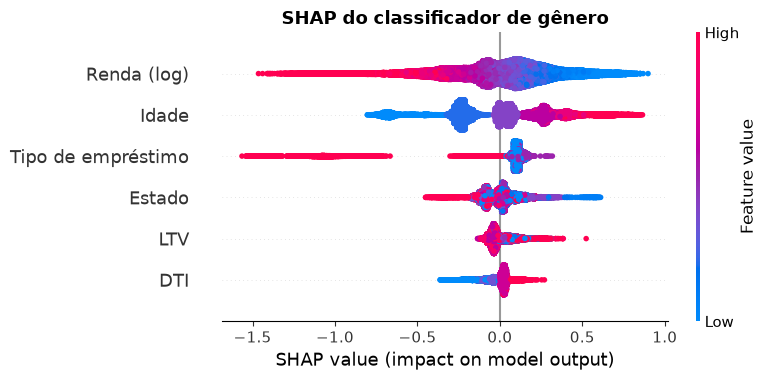

In [10]:
shap_genero.feature_names = [nomes[a] for a in atributos]
shap.plots.beeswarm(shap_genero, show=False)
plt.title("SHAP do classificador de gênero", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../figuras/proxies_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

### 6. Como os proxies diferem entre homens e mulheres

Para entender o que o SHAP encontrou, comparamos diretamente as variáveis mais importantes entre homens e mulheres na base inteira.

In [11]:
comparacao = pd.DataFrame({
    "Renda mediana (mil US$)": data.groupby("mulher")["log_renda"].median().map(np.exp),
    "Idade: até 34 anos (%)": data.groupby("mulher")["applicant_age"].apply(lambda x: 100 * (x <= 1).mean()),
    "Idade: 55 anos ou mais (%)": data.groupby("mulher")["applicant_age"].apply(lambda x: 100 * (x >= 4).mean()),
    "Empréstimo FHA (%)": data.groupby("mulher")["loan_type"].apply(lambda x: 100 * (x == 2).mean()),
    "Empréstimo VA (%)": data.groupby("mulher")["loan_type"].apply(lambda x: 100 * (x == 3).mean()),
    "LTV mediano": data.groupby("mulher")["ltv"].median(),
    "DTI 50% ou mais (%)": data.groupby("mulher")["dti"].apply(lambda x: 100 * (x >= 4).mean()),
}).T
comparacao.columns = ["Homens", "Mulheres"]
comparacao.round(1)

,Homens,Mulheres
Renda mediana (mil US$),95.0,82.0
Idade: até 34 anos (%),42.8,32.9
Idade: 55 anos ou mais (%),14.6,22.3
Empréstimo FHA (%),22.3,27.3
Empréstimo VA (%),12.7,4.5
LTV mediano,95.0,93.3
DTI 50% ou mais (%),13.9,15.1


**Tipos de empréstimo:** 1 = convencional, 2 = FHA (garantido pelo governo, comum para quem tem menos entrada ou crédito), 3 = VA (para veteranos militares), 4 = USDA (rural).

### 7. Quais variáveis explicam a diferença na negação?

As seções anteriores mostram quais variáveis **carregam** informação de gênero. Agora perguntamos algo mais direto: **quais variáveis fazem o modelo de crédito negar mais as mulheres?**

Para isso, treinamos novamente o modelo de crédito **sem gênero**, com as mesmas variáveis (agora codificadas como inteiros) e os mesmos hiperparâmetros do notebook 05, e conferimos que o desempenho é o mesmo.

In [12]:
modelo_credito = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, max_iter=300,
                                                early_stopping=True, random_state=SEMENTE)
modelo_credito.fit(treino[atributos], treino["negado"])

auc_credito = roc_auc_score(teste["negado"], modelo_credito.predict_proba(teste[atributos])[:, 1])
print(f"AUC do modelo de crédito sem gênero: {auc_credito:.4f}  (notebook 05: 0,7867)")

AUC do modelo de crédito sem gênero: 0.7848  (notebook 05: 0,7867)


Os valores SHAP têm uma propriedade útil: **somados, eles dão a previsão do modelo** (em escala de log-odds). Então, se calcularmos a média dos valores SHAP de cada variável **entre as mulheres** e **entre os homens**, a diferença entre essas médias mostra **quanto cada variável contribui para a diferença** na previsão entre os dois grupos.

- contribuição **positiva**: a variável faz o modelo prever **mais negação** para mulheres;
- contribuição **negativa**: faz prever **menos** negação para mulheres.

In [13]:
explicador_credito = shap.TreeExplainer(modelo_credito)
shap_credito = explicador_credito(amostra[atributos])

eh_mulher = amostra["mulher"].values == 1
contribuicao = pd.Series(
    shap_credito.values[eh_mulher].mean(axis=0) - shap_credito.values[~eh_mulher].mean(axis=0),
    index=atributos).rename(index=nomes).sort_values()

print(f"Diferença total na previsão (log-odds), mulheres - homens: {contribuicao.sum():.4f}")
contribuicao.round(4)

Diferença total na previsão (log-odds), mulheres - homens: 0.1402


LTV                  -0.0129
Estado                0.0002
DTI                   0.0174
Idade                 0.0207
Tipo de empréstimo    0.0419
Renda (log)           0.0729
dtype: float64

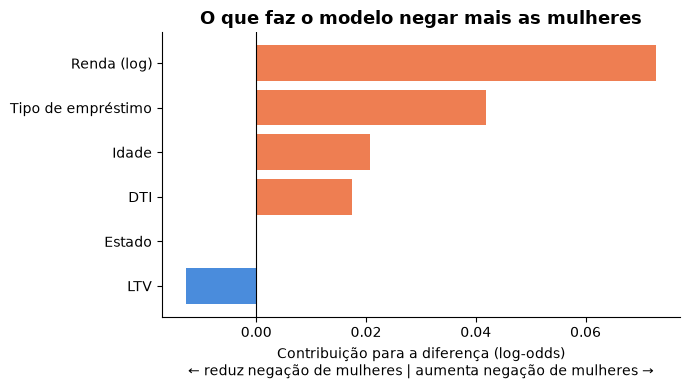

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
cores = [ORANGE if v > 0 else BLUE for v in contribuicao.values]
ax.barh(contribuicao.index, contribuicao.values, color=cores, alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Contribuição para a diferença (log-odds)\n← reduz negação de mulheres | aumenta negação de mulheres →")
ax.set_title("O que faz o modelo negar mais as mulheres", fontsize=13, fontweight="bold")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/proxies_contribuicao_negacao.png", dpi=150)
plt.show()

### 8. Salvando os resultados

In [15]:
tabela = pd.DataFrame({
    "Importância para prever o gênero (SHAP)": importancia_genero,
    "Contribuição para a diferença na negação (log-odds)": contribuicao,
}).sort_values("Importância para prever o gênero (SHAP)", ascending=False)

with open("../resultados/proxies_shap.md", "w", encoding="utf-8") as f:
    f.write(f"Classificador de gênero: AUC = {auc_genero:.4f} (IC 95%: {ic_inf:.4f} a {ic_sup:.4f}), "
            f"teste com {len(teste):,} pedidos.\n\n")
    f.write(tabela.round(4).to_markdown())
    f.write("\n\nImportância: média do |SHAP| do classificador de gênero (amostra de 50 mil pedidos do teste). "
            "Contribuição: média do SHAP do modelo de crédito sem gênero entre mulheres menos entre homens.\n")
tabela.round(4)

,Importância para prever o gênero (SHAP),Contribuição para a diferença na negação (log-odds)
Renda (log),0.2546,0.0729
Idade,0.2468,0.0207
Tipo de empréstimo,0.1986,0.0419
Estado,0.0763,0.0002
LTV,0.0559,-0.0129
DTI,0.0495,0.0174


### Conclusão

- **As variáveis do modelo denunciam o gênero.** Usando só renda, LTV, DTI, tipo de empréstimo, estado e idade, um classificador adivinha o gênero com **AUC = 0,664** (IC 95%: 0,663 a 0,666), bem acima do "chute" (0,5). É um sinal **moderado**: as variáveis não revelam o gênero com certeza, mas carregam informação suficiente para o modelo de crédito "enxergá-lo" indiretamente.
- **Os três principais proxies** (maior importância SHAP) são:
  1. **Renda**: as mulheres da amostra têm renda mediana de 82 mil dólares, contra 95 mil dos homens. No *beeswarm*, renda baixa (pontos azuis) empurra a previsão para "mulher";
  2. **Idade**: as mulheres solicitantes são mais velhas (22% têm 55 anos ou mais, contra 15% dos homens);
  3. **Tipo de empréstimo**: os empréstimos **VA** (para veteranos militares) são quase exclusivos dos homens (12,7% contra 4,5%), e as mulheres usam mais o **FHA** (27% contra 22%).
- Estado, LTV e DTI carregam pouca informação sobre o gênero.
- **O que faz o modelo negar mais as mulheres:** a diferença na previsão de negação vem principalmente da **renda** (cerca de metade do total) e do **tipo de empréstimo** (cerca de 30%), seguidos por idade e DTI. O LTV atua no sentido contrário, porque as mulheres têm LTV ligeiramente menor (dão entrada maior).
- O caso do **tipo de empréstimo** é ilustrativo: o empréstimo VA tem taxa de negação muito baixa (odds ratio de 0,34 na Etapa B), e quase só homens têm acesso a ele, por serem veteranos. O modelo aprende que VA significa "aprovar", o que favorece os homens **sem nunca ver o gênero**.
- **Ligação com as etapas anteriores:** a Etapa B mostrou que, **para perfis iguais**, os bancos não tratam homens e mulheres de forma diferente. As diferenças vêm de **perfis diferentes** (renda, idade, acesso ao VA), e são exatamente essas variáveis que funcionam como proxies. Retirar a variável gênero do modelo não remove essas diferenças, e o limiar de decisão as amplifica (Etapa E).

**Observação:** neste notebook, as categóricas foram convertidas em inteiros para permitir o SHAP. O modelo de crédito retreinado assim tem AUC de 0,785, praticamente igual ao do notebook 05 (0,787).